In [1]:
!pip install -q ultralytics transformers timm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.0 MB/s eta 0:00:00


In [2]:
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

from ultralytics import YOLO
from google.colab import files

from transformers import AutoImageProcessor
from transformers import AutoModel

import torch.nn as nn

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cpu


In [ ]:
yolo = YOLO("/content/drive/MyDrive/Copy of v8_75.pt")

In [ ]:
from transformers import AutoImageProcessor
from transformers import AutoModel

processor = AutoImageProcessor.from_pretrained(
    "facebook/dinov2-base"
)

dinov2 = AutoModel.from_pretrained(
    "facebook/dinov2-base"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dinov2.to(device)
dinov2.eval()

print("DINOv2 Loaded Successfully!")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

DINOv2 Loaded Successfully!


In [ ]:
import torch.nn as nn

class CoffeeMLP(nn.Module):

    def __init__(self):

        super().__init__()

        self.model = nn.Sequential(

            nn.Linear(768,512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(512,256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(256,7)

        )

    def forward(self,x):

        return self.model(x)

In [ ]:
mlp = CoffeeMLP().to(device)

mlp.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/DINO_Features/mlp_classifier.pth",
        map_location=device
    )
)

mlp.eval()

print("MLP Loaded Successfully!")

MLP Loaded Successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print(image_path)

Saving IMG_20260708_183457_jpg.rf.1ebd4126c5821a0e64348bb109fd46e4.jpg to IMG_20260708_183457_jpg.rf.1ebd4126c5821a0e64348bb109fd46e4.jpg
IMG_20260708_183457_jpg.rf.1ebd4126c5821a0e64348bb109fd46e4.jpg


In [ ]:
results = yolo.predict(
    source=image_path,
    conf=0.5
)

result = results[0]


image 1/1 /content/IMG_20260708_183457_jpg.rf.1ebd4126c5821a0e64348bb109fd46e4.jpg: 1024x1024 6 goods, 7 shells, 23.7ms
Speed: 26.6ms preprocess, 23.7ms inference, 5.1ms postprocess per image at shape (1, 3, 1024, 1024)


In [ ]:
image = result.orig_img

masks = result.masks

boxes = result.boxes

In [ ]:
print("Beans detected:", len(masks.data))

Beans detected: 13


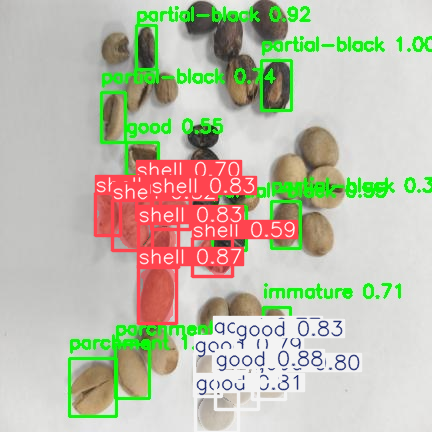

In [ ]:
result.show()

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

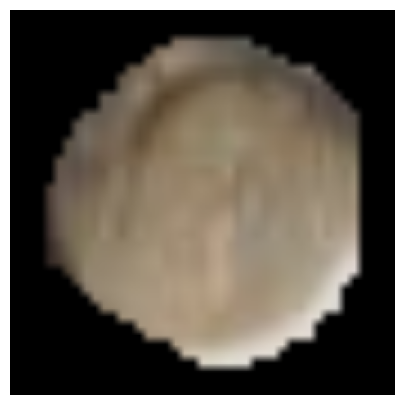

In [ ]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

mask = masks.data[0].cpu().numpy()

mask = cv2.resize(
    mask,
    (image.shape[1], image.shape[0]),
    interpolation=cv2.INTER_NEAREST
)

mask = (mask > 0.5).astype(np.uint8)

bean = image.copy()

bean[mask == 0] = 0

x1, y1, x2, y2 = boxes.xyxy[0].cpu().numpy().astype(int)

bean = bean[y1:y2, x1:x2]

bean = cv2.resize(bean, (224,224))

plt.figure(figsize=(5,5))
plt.imshow(cv2.cvtColor(bean, cv2.COLOR_BGR2RGB))
plt.axis("off")

In [ ]:
bean_rgb = cv2.cvtColor(bean, cv2.COLOR_BGR2RGB)

bean_pil = Image.fromarray(bean_rgb)

In [ ]:
inputs = processor(
    images=bean_pil,
    return_tensors="pt"
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():

    outputs = dinov2(**inputs)

feature = outputs.last_hidden_state[:, 0, :]

In [ ]:
print(feature.shape)

torch.Size([1, 768])


In [ ]:
with torch.no_grad():

    prediction = mlp(feature)

    probabilities = torch.softmax(prediction, dim=1)

    predicted_class = torch.argmax(probabilities, dim=1).item()

    confidence = probabilities[0][predicted_class].item()

In [ ]:
class_names = {
    0: "cut",
    1: "good",
    2: "husk",
    3: "immature",
    4: "parchment",
    5: "partial-black",
    6: "shell"
}

print("Prediction :", class_names[predicted_class])
print("Confidence :", confidence)

Prediction : immature
Confidence : 0.616556704044342


In [ ]:
import cv2
import numpy as np
from PIL import Image
import torch

class_names = {
    0: "cut",
    1: "good",
    2: "husk",
    3: "immature",
    4: "parchment",
    5: "partial-black",
    6: "shell"
}

annotated = image.copy()
predictions = []

for i in range(len(masks.data)):

    # ----------------------------
    # Get Mask
    # ----------------------------
    mask = masks.data[i].cpu().numpy()

    mask = cv2.resize(
        mask,
        (image.shape[1], image.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    mask = (mask > 0.5).astype(np.uint8)

    # ----------------------------
    # Extract Bean
    # ----------------------------
    bean = image.copy()
    bean[mask == 0] = 0

    x1, y1, x2, y2 = boxes.xyxy[i].cpu().numpy().astype(int)

    bean_crop = bean[y1:y2, x1:x2]

    bean_crop = cv2.resize(bean_crop, (224,224))

    # ----------------------------
    # DINOv2 Feature Extraction
    # ----------------------------
    bean_rgb = cv2.cvtColor(bean_crop, cv2.COLOR_BGR2RGB)
    bean_pil = Image.fromarray(bean_rgb)

    inputs = processor(
        images=bean_pil,
        return_tensors="pt"
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = dinov2(**inputs)

    feature = outputs.last_hidden_state[:,0,:]

    # ----------------------------
    # MLP Prediction
    # ----------------------------
    with torch.no_grad():

        prediction = mlp(feature)

        probability = torch.softmax(prediction, dim=1)

        predicted = torch.argmax(probability, dim=1).item()

        confidence = probability[0][predicted].item()

    label = f"{class_names[predicted]} {confidence:.2f}"

    predictions.append({
            "bean": i + 1,
            "label": class_names[predicted],
            "confidence": confidence
        })


    # ----------------------------
    # Draw Results
    # ----------------------------
    cv2.rectangle(
        annotated,
        (x1,y1),
        (x2,y2),
        (0,255,0),
        2
    )

    cv2.putText(
        annotated,
        label,
        (x1,max(y1-10,20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0,255,0),
        2
    )

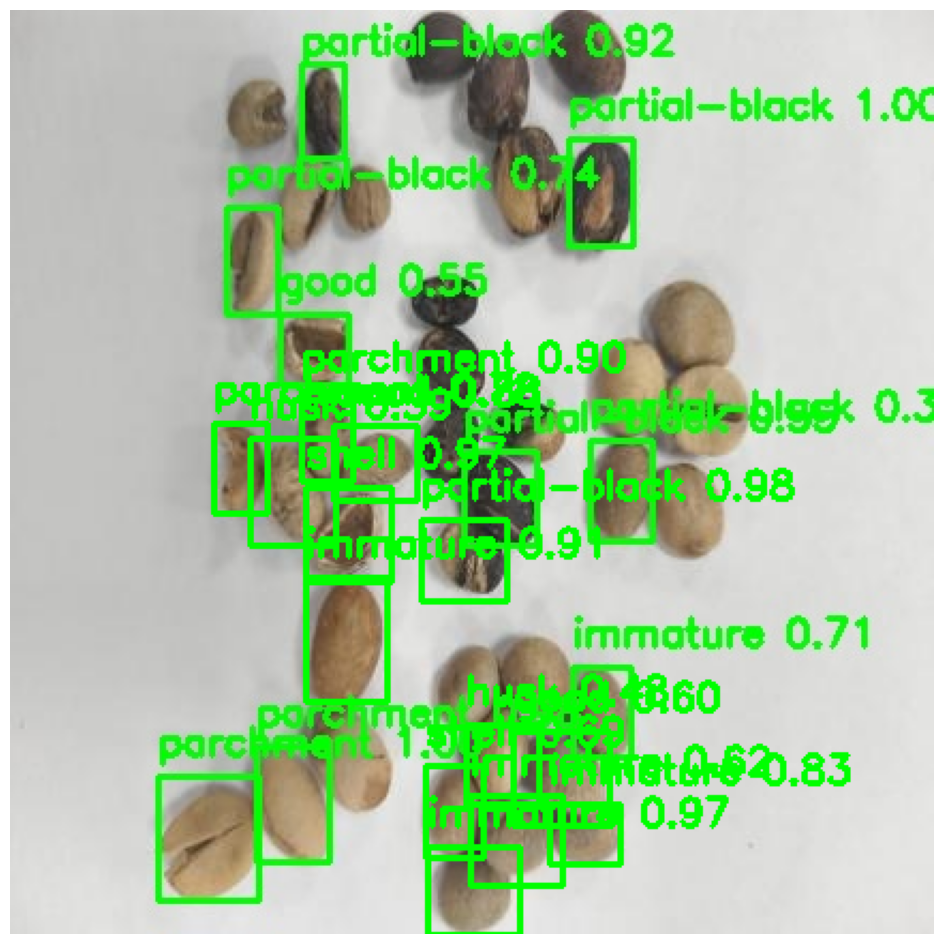

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,12))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
cv2.imwrite("Final_Result.jpg", annotated)

True